# 04 - Classical CNN Baseline

## Objective

This notebook implements a classical CNN + Softmax baseline for iris recognition.

The data used in this notebook comes from the training identities generated in
Notebook 3.

Since Notebook 3 uses identity-disjoint train, validation, and test splits,
the identities in its validation and test sets are unseen during CNN training.
A conventional Softmax classifier cannot directly classify completely unseen
identities.

Therefore, this notebook creates an internal closed-set split from the
Notebook 3 training identities.

For each training identity:

- 8 images → CNN training
- 1 image → validation
- 1 image → closed-set baseline test

The trained CNN provides:

1. A classical iris identification baseline.
2. A Softmax classification baseline for comparison.
3. A CNN feature extractor that will be useful in later notebooks.

The identity-disjoint validation/test sets and 1-shot/3-shot/5-shot protocols
created in Notebook 3 remain reserved for the metric-learning and few-shot
experiments in later notebooks.

In [24]:
import torch
print(torch.__version__)
print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0))

2.14.0+cu126
True
NVIDIA GeForce GTX 1650


In [25]:
# ============================================================
# CELL 1: Import PyTorch and Torchvision
# ============================================================

import math

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader

from torchvision import transforms
from torchvision.models import (
    resnet18, ResNet18_Weights,
    resnet34, ResNet34_Weights,
    resnet50, ResNet50_Weights,
)

print("PyTorch and Torchvision imported successfully.")

# ============================================================
# CELL 2: Import libraries
# ============================================================

import os
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

from sklearn.metrics import accuracy_score

from tqdm.auto import tqdm

print("Libraries imported successfully.")


PyTorch and Torchvision imported successfully.
Libraries imported successfully.


In [26]:
# ============================================================
# CELL 3: Reproducibility
# ============================================================

SEED = 42


def set_seed(seed=SEED):

    random.seed(seed)

    np.random.seed(seed)

    torch.manual_seed(seed)

    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True

    torch.backends.cudnn.benchmark = False


set_seed()

print("Random seed set to:", SEED)

Random seed set to: 42


In [27]:
# ============================================================
# CELL 4: Configuration
# ============================================================

DATA_SPLITS_ROOT = Path("../data_splits")

OUTPUT_DIR = Path("../classical_cnn_baseline")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

BACKBONE = "resnet34"

IMAGE_SIZE = 224
BATCH_SIZE = 24               # resnet34 fits comfortably at batch 24 on 4GB VRAM
NUM_EPOCHS = 70

BACKBONE_LR = 3e-4
HEAD_LR = 1e-3
WEIGHT_DECAY = 8e-4           # raised: fight the overfitting seen last run

WARMUP_EPOCHS = 3
LABEL_SMOOTHING = 0.1
EMBEDDING_DIM = 512

USE_ARCFACE = True
ARC_SCALE = 30.0
ARC_MARGIN = 0.20             # lowered: 0.30 drove train acc to 98% by epoch 20

PATIENCE = 15
NUM_WORKERS = 0

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = False                # GTX 1650 has no Tensor Cores - keep this off
USE_CHANNELS_LAST = DEVICE.type == "cuda"

print("Data splits directory:", DATA_SPLITS_ROOT)
print("Output directory:", OUTPUT_DIR)
print("Backbone:", BACKBONE)
print("Device:", DEVICE)
print("Mixed precision:", USE_AMP)
print("Epochs:", NUM_EPOCHS)
print("Backbone LR:", BACKBONE_LR, "| Head LR:", HEAD_LR)
print("ArcFace head:", USE_ARCFACE)

if DEVICE.type == "cpu":
    print("\n[WARNING] No GPU detected.")

Data splits directory: ..\data_splits
Output directory: ..\classical_cnn_baseline
Backbone: resnet34
Device: cuda
Mixed precision: False
Epochs: 70
Backbone LR: 0.0003 | Head LR: 0.001
ArcFace head: True


In [28]:
# ============================================================
# CELL 5: Locate Notebook 3 split files
# ============================================================

if not DATA_SPLITS_ROOT.exists():

    raise FileNotFoundError(
        f"Notebook 3 output directory was not found:\n"
        f"{DATA_SPLITS_ROOT}"
    )


print("Files available in Notebook 3 output directory:\n")

available_files = sorted(
    [
        file.name
        for file in DATA_SPLITS_ROOT.iterdir()
        if file.is_file()
    ]
)

for file_name in available_files:
    print("-", file_name)


def find_csv(possible_names):

    for name in possible_names:

        path = DATA_SPLITS_ROOT / name

        if path.exists():
            return path

    return None


TRAIN_CSV = find_csv(
    [
        "train.csv",
        "training.csv"
    ]
)


VALIDATION_CSV = find_csv(
    [
        "validation.csv",
        "val.csv"
    ]
)


TEST_CSV = find_csv(
    [
        "test.csv"
    ]
)


if TRAIN_CSV is None:

    raise FileNotFoundError(
        "Could not find the training CSV generated by Notebook 3."
    )


print("\nDetected files:")

print("Train CSV      :", TRAIN_CSV)

print("Validation CSV :", VALIDATION_CSV)

print("Test CSV       :", TEST_CSV)

Files available in Notebook 3 output directory:

- 1shot_test_query.csv
- 1shot_test_support.csv
- 1shot_train_query.csv
- 1shot_train_support.csv
- 1shot_validation_query.csv
- 1shot_validation_support.csv
- 3shot_test_query.csv
- 3shot_test_support.csv
- 3shot_train_query.csv
- 3shot_train_support.csv
- 3shot_validation_query.csv
- 3shot_validation_support.csv
- 5shot_test_query.csv
- 5shot_test_support.csv
- 5shot_train_query.csv
- 5shot_train_support.csv
- 5shot_validation_query.csv
- 5shot_validation_support.csv
- few_shot_summary.csv
- reconstructed_metadata.csv
- test.csv
- train.csv
- validation.csv

Detected files:
Train CSV      : ..\data_splits\train.csv
Validation CSV : ..\data_splits\validation.csv
Test CSV       : ..\data_splits\test.csv


In [29]:
# ============================================================
# CELL 6: Load Notebook 3 training split
# ============================================================

train_df = pd.read_csv(
    TRAIN_CSV
)


print("Notebook 3 training split loaded successfully.")

print("\nDataset shape:")

print(train_df.shape)


print("\nColumns:")

print(
    train_df.columns.tolist()
)


display(
    train_df.head()
)

Notebook 3 training split loaded successfully.

Dataset shape:
(14000, 6)

Columns:
['subject_id', 'eye', 'identity', 'image_index', 'image_name', 'processed_path']


,subject_id,eye,identity,image_index,image_name,processed_path
0,0,L,000-L,0,000_L_00_norm.png,..\outputs\preprocessed_iris\000_L_00_norm.png
1,0,L,000-L,1,000_L_01_norm.png,..\outputs\preprocessed_iris\000_L_01_norm.png
2,0,L,000-L,2,000_L_02_norm.png,..\outputs\preprocessed_iris\000_L_02_norm.png
3,0,L,000-L,3,000_L_03_norm.png,..\outputs\preprocessed_iris\000_L_03_norm.png
4,0,L,000-L,4,000_L_04_norm.png,..\outputs\preprocessed_iris\000_L_04_norm.png


In [30]:
# ============================================================
# CELL 7: Identify important columns
# ============================================================

IDENTITY_CANDIDATES = [

    "identity",
    "eye_id",
    "subject_id",
    "class_id"

]


PATH_CANDIDATES = [

    "processed_path",
    "image_path",
    "path"

]


def find_column(
    dataframe,
    candidates
):

    for column in candidates:

        if column in dataframe.columns:
            return column

    return None


IDENTITY_COLUMN = find_column(
    train_df,
    IDENTITY_CANDIDATES
)


PATH_COLUMN = find_column(
    train_df,
    PATH_CANDIDATES
)


if IDENTITY_COLUMN is None:

    raise ValueError(
        f"Could not identify identity column.\n"
        f"Available columns: {train_df.columns.tolist()}"
    )


if PATH_COLUMN is None:

    raise ValueError(
        f"Could not identify image path column.\n"
        f"Available columns: {train_df.columns.tolist()}"
    )


print("Identity column detected:", IDENTITY_COLUMN)

print("Image path column detected:", PATH_COLUMN)

Identity column detected: identity
Image path column detected: processed_path


In [31]:
# ============================================================
# CELL 8: Validate training dataset
# ============================================================

print("=" * 60)

print("VALIDATING NOTEBOOK 3 TRAINING SPLIT")

print("=" * 60)


print("\nTotal images:")

print(
    len(train_df)
)


print("\nUnique identities:")

print(
    train_df[IDENTITY_COLUMN].nunique()
)


images_per_identity = (
    train_df
    .groupby(IDENTITY_COLUMN)
    .size()
)


print("\nImages per identity:")

print(
    images_per_identity.value_counts()
    .sort_index()
)


print("\nMinimum images per identity:")

print(
    images_per_identity.min()
)


print("\nMaximum images per identity:")

print(
    images_per_identity.max()
)


missing_files = train_df[
    ~train_df[PATH_COLUMN]
    .apply(
        lambda path: os.path.exists(path)
    )
]


print("\nMissing image files:")

print(
    len(missing_files)
)


if len(missing_files) > 0:

    print("\nFirst missing paths:")

    display(
        missing_files.head()
    )

    raise FileNotFoundError(
        "Some image paths do not exist."
    )


print("\n✓ Training dataset validation completed successfully.")

VALIDATING NOTEBOOK 3 TRAINING SPLIT

Total images:
14000

Unique identities:
1400

Images per identity:
10    1400
Name: count, dtype: int64

Minimum images per identity:
10

Maximum images per identity:
10



Missing image files:
0

✓ Training dataset validation completed successfully.


In [32]:
# ============================================================
# CELL 9: Create internal closed-set split
# ============================================================

train_records = []

validation_records = []

closed_test_records = []


for identity, group in train_df.groupby(
    IDENTITY_COLUMN
):

    group = group.sample(
        frac=1,
        random_state=SEED
    ).reset_index(
        drop=True
    )


    if len(group) < 3:

        raise ValueError(
            f"Identity {identity} has only "
            f"{len(group)} images."
        )


    # --------------------------------------------------------
    # For 10-image identities:
    #
    # 8 -> Training
    # 1 -> Validation
    # 1 -> Closed-set test
    # --------------------------------------------------------

    train_part = group.iloc[:-2]

    validation_part = group.iloc[-2:-1]

    test_part = group.iloc[-1:]


    train_records.append(
        train_part
    )

    validation_records.append(
        validation_part
    )

    closed_test_records.append(
        test_part
    )


baseline_train_df = pd.concat(
    train_records,
    ignore_index=True
)


baseline_validation_df = pd.concat(
    validation_records,
    ignore_index=True
)


baseline_test_df = pd.concat(
    closed_test_records,
    ignore_index=True
)


print("Internal closed-set split created successfully.")

Internal closed-set split created successfully.


In [33]:
# ============================================================
# CELL 10: Verify internal split
# ============================================================

print("=" * 60)

print("INTERNAL CLOSED-SET SPLIT SUMMARY")

print("=" * 60)


print("\nTraining images:")

print(
    len(baseline_train_df)
)


print(
    "Training identities:",
    baseline_train_df[IDENTITY_COLUMN].nunique()
)


print("\nValidation images:")

print(
    len(baseline_validation_df)
)


print(
    "Validation identities:",
    baseline_validation_df[IDENTITY_COLUMN].nunique()
)


print("\nClosed-set test images:")

print(
    len(baseline_test_df)
)


print(
    "Closed-set test identities:",
    baseline_test_df[IDENTITY_COLUMN].nunique()
)


train_ids = set(
    baseline_train_df[
        IDENTITY_COLUMN
    ].unique()
)


validation_ids = set(
    baseline_validation_df[
        IDENTITY_COLUMN
    ].unique()
)


test_ids = set(
    baseline_test_df[
        IDENTITY_COLUMN
    ].unique()
)


print("\nIdentity overlap checks:")

print(
    "Train / Validation:",
    len(train_ids & validation_ids)
)


print(
    "Train / Closed-test:",
    len(train_ids & test_ids)
)


print(
    "Validation / Closed-test:",
    len(validation_ids & test_ids)
)


if (
    train_ids ==
    validation_ids ==
    test_ids
):

    print(
        "\n✓ Closed-set split verified."
    )

else:

    raise ValueError(
        "Internal closed-set identities are inconsistent."
    )

INTERNAL CLOSED-SET SPLIT SUMMARY

Training images:
11200
Training identities: 1400

Validation images:
1400
Validation identities: 1400

Closed-set test images:
1400
Closed-set test identities: 1400

Identity overlap checks:
Train / Validation: 1400
Train / Closed-test: 1400
Validation / Closed-test: 1400

✓ Closed-set split verified.


In [34]:
# ============================================================
# CELL 11: Create identity to class mapping
# ============================================================

identities = sorted(
    baseline_train_df[
        IDENTITY_COLUMN
    ].unique()
)


identity_to_label = {

    identity: index

    for index, identity
    in enumerate(identities)

}


label_to_identity = {

    index: identity

    for identity, index
    in identity_to_label.items()

}


NUM_CLASSES = len(
    identity_to_label
)


print(
    "Number of CNN classes:",
    NUM_CLASSES
)

Number of CNN classes: 1400


In [35]:
# ============================================================
# CELL 12: Add numerical labels
# ============================================================

for dataframe in [

    baseline_train_df,
    baseline_validation_df,
    baseline_test_df

]:

    dataframe[
        "label"
    ] = dataframe[
        IDENTITY_COLUMN
    ].map(
        identity_to_label
    )


print("Numerical labels created successfully.")

Numerical labels created successfully.


In [36]:
# ============================================================
# CELL 13: Save baseline splits
# ============================================================

baseline_train_df.to_csv(
    OUTPUT_DIR / "baseline_train.csv",
    index=False
)


baseline_validation_df.to_csv(
    OUTPUT_DIR / "baseline_validation.csv",
    index=False
)


baseline_test_df.to_csv(
    OUTPUT_DIR / "baseline_closed_set_test.csv",
    index=False
)


print(
    "Baseline CSV files saved successfully."
)

Baseline CSV files saved successfully.


In [37]:
# ============================================================
# CELL 14: Image transformations
# ============================================================

# The original augmentation (5 degree rotation + 0.15 jitter) was far
# too weak for 8 images per identity - the model memorised the training
# images within a few epochs. Stronger geometric + occlusion
# augmentation is what closes the train/validation gap here.
#
# NOTE: no horizontal flip. Identity = subject + eye, and flipping a
# left iris makes it look like a right iris, which corrupts the label.

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]


train_transform = transforms.Compose(
    [
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),

        # Geometric variation: pose, small head tilt, scale of the iris
        transforms.RandomApply(
            [
                transforms.RandomAffine(
                    degrees=10,
                    translate=(0.06, 0.06),
                    scale=(0.90, 1.10),
                    shear=4,
                    fill=0,
                )
            ],
            p=0.8,
        ),

        # Illumination variation (NIR sensors vary a lot)
        transforms.ColorJitter(brightness=0.30, contrast=0.30),

        # Focus / sensor variation
        transforms.RandomApply(
            [transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 1.2))],
            p=0.25,
        ),

        transforms.ToTensor(),

        transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),

        # Simulates eyelid / eyelash / specular occlusion
        transforms.RandomErasing(
            p=0.35,
            scale=(0.02, 0.15),
            ratio=(0.3, 3.3),
            value=0,
        ),
    ]
)


evaluation_transform = transforms.Compose(
    [
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ]
)


print("Image transformations configured.")


Image transformations configured.


In [38]:
# ============================================================
# CELL 15: Custom iris dataset
# ============================================================

class IrisDataset(Dataset):


    def __init__(
        self,
        dataframe,
        transform=None
    ):

        self.dataframe = (
            dataframe
            .reset_index(drop=True)
        )

        self.transform = transform


    def __len__(self):

        return len(
            self.dataframe
        )


    def __getitem__(
        self,
        index
    ):

        row = self.dataframe.iloc[index]


        image_path = row[
            PATH_COLUMN
        ]


        label = int(
            row["label"]
        )


        image = Image.open(
            image_path
        ).convert(
            "RGB"
        )


        if self.transform is not None:

            image = self.transform(
                image
            )


        return image, label

In [39]:
# ============================================================
# CELL 16: Create datasets and DataLoaders
# ============================================================

train_dataset = IrisDataset(
    baseline_train_df,
    transform=train_transform
)

validation_dataset = IrisDataset(
    baseline_validation_df,
    transform=evaluation_transform
)

test_dataset = IrisDataset(
    baseline_test_df,
    transform=evaluation_transform
)


loader_kwargs = {
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "pin_memory": DEVICE.type == "cuda",
}

if NUM_WORKERS > 0:
    loader_kwargs["persistent_workers"] = True
    loader_kwargs["prefetch_factor"] = 4


train_loader = DataLoader(
    train_dataset,
    shuffle=True,
    drop_last=True,        # keeps BatchNorm statistics stable
    **loader_kwargs
)

validation_loader = DataLoader(
    validation_dataset,
    shuffle=False,
    **loader_kwargs
)

test_loader = DataLoader(
    test_dataset,
    shuffle=False,
    **loader_kwargs
)


print("DataLoaders created successfully.")
print("\nTrain batches:", len(train_loader))
print("Validation batches:", len(validation_loader))
print("Test batches:", len(test_loader))


DataLoaders created successfully.

Train batches: 466
Validation batches: 59
Test batches: 59


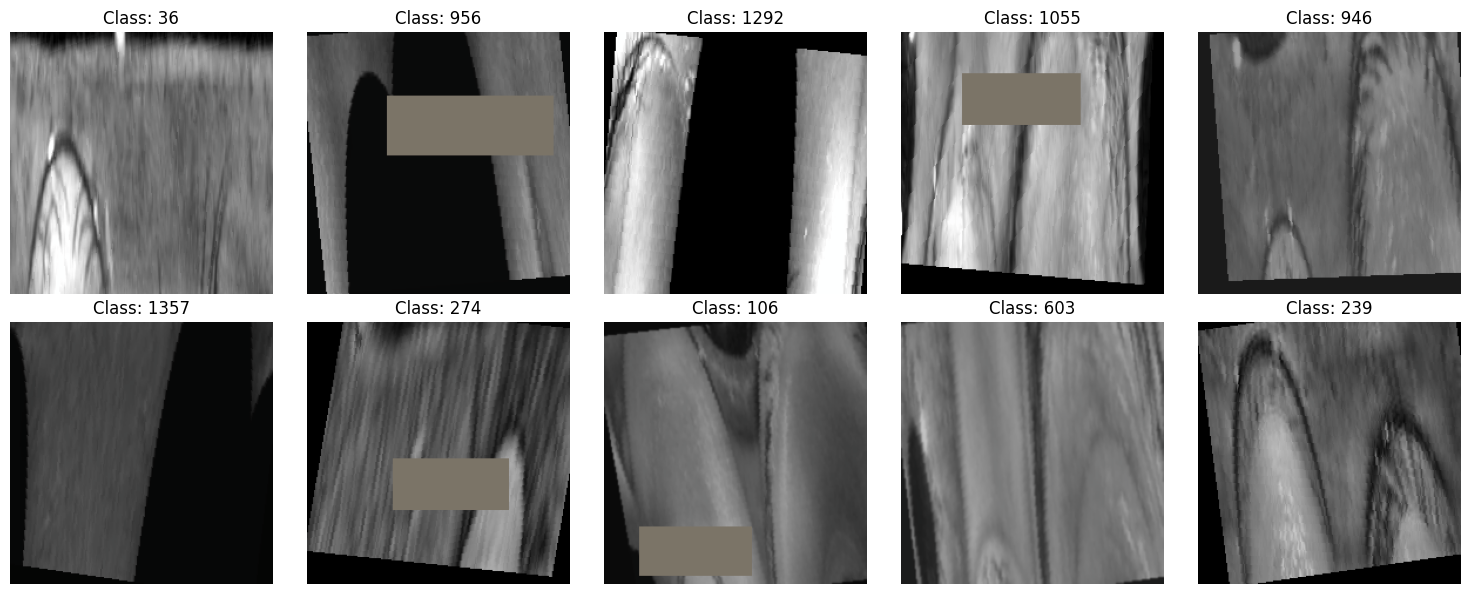

In [40]:
# ============================================================
# CELL 17: Visualize training samples
# ============================================================

images, labels = next(iter(train_loader))

# ImageNet normalization values
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

fig, axes = plt.subplots(
    2,
    5,
    figsize=(15, 6)
)

for index, axis in enumerate(axes.flat):

    image = images[index]

    image = image.permute(
        1, 2, 0
    ).numpy()

    # Denormalize
    image = image * std + mean

    # Keep pixel values between 0 and 1
    image = np.clip(image, 0, 1)

    axis.imshow(image)

    axis.set_title(
        f"Class: {labels[index].item()}"
    )

    axis.axis("off")

plt.tight_layout()
plt.show()

In [41]:
# ============================================================
# CELL 18: Backbone + BN-neck + ArcFace head
# ============================================================
#
# Three changes vs. the original model, in order of importance:
#
# 1. ArcFace classifier instead of a plain Linear softmax. With 1400
#    identities and 8 images each, an angular margin gives much more
#    separable classes.
# 2. The 128-d ReLU bottleneck is gone. ReLU before the classifier
#    throws away half of every embedding; 128 dims is also not enough
#    to linearly separate 1400 identities. Replaced with a 512-d
#    "BN-neck" (Linear -> BatchNorm1d), the standard choice in
#    re-identification work.
# 3. Dropout is applied to the embedding only, at a lower rate.


class ArcMarginProduct(nn.Module):
    """ArcFace: additive angular margin softmax (numerically stable form)."""

    def __init__(self, in_features, out_features,
                 scale=30.0, margin=0.30, easy_margin=False):

        super().__init__()

        self.in_features = in_features
        self.out_features = out_features
        self.scale = scale
        self.margin = margin
        self.easy_margin = easy_margin

        self.weight = nn.Parameter(
            torch.empty(out_features, in_features)
        )
        nn.init.xavier_normal_(self.weight)

        # Precomputed constants - avoids acos() entirely, which is what
        # was producing NaN gradients near cosine = +-1.
        self.cos_m = math.cos(margin)
        self.sin_m = math.sin(margin)
        self.th = math.cos(math.pi - margin)
        self.mm = math.sin(math.pi - margin) * margin

    def forward(self, embeddings, labels=None):

        cosine = F.linear(
            F.normalize(embeddings.float()),
            F.normalize(self.weight.float()),
        )

        if labels is None:
            return cosine * self.scale

        sine = torch.sqrt(
            (1.0 - torch.pow(cosine, 2)).clamp(min=0.0, max=1.0)
        )

        phi = cosine * self.cos_m - sine * self.sin_m

        if self.easy_margin:
            phi = torch.where(cosine > 0, phi, cosine)
        else:
            # Falls back to plain cosine once theta+margin would exceed pi
            phi = torch.where(cosine > self.th, phi, cosine - self.mm)

        one_hot = F.one_hot(
            labels, num_classes=self.out_features
        ).to(cosine.dtype)

        output = one_hot * phi + (1.0 - one_hot) * cosine

        return output * self.scale


def build_backbone(name):

    if name == "resnet18":
        model = resnet18(weights=ResNet18_Weights.DEFAULT)
    elif name == "resnet34":
        model = resnet34(weights=ResNet34_Weights.DEFAULT)
    elif name == "resnet50":
        model = resnet50(weights=ResNet50_Weights.DEFAULT)
    else:
        raise ValueError(f"Unknown backbone: {name}")

    num_features = model.fc.in_features
    model.fc = nn.Identity()

    return model, num_features


class ClassicalCNN(nn.Module):

    def __init__(self, num_classes,
                 embedding_dim=EMBEDDING_DIM,
                 backbone_name=BACKBONE,
                 use_arcface=USE_ARCFACE,
                 dropout=0.2):

        super().__init__()

        self.backbone, num_features = build_backbone(backbone_name)

        self.use_arcface = use_arcface

        # BN-neck: no ReLU, so negative directions are preserved.
        self.embedding_layer = nn.Sequential(
            nn.Linear(num_features, embedding_dim, bias=False),
            nn.BatchNorm1d(embedding_dim),
        )

        self.dropout = nn.Dropout(dropout)

        if use_arcface:
            self.classifier = ArcMarginProduct(
                embedding_dim,
                num_classes,
                scale=ARC_SCALE,
                margin=ARC_MARGIN,
            )
        else:
            self.classifier = nn.Linear(embedding_dim, num_classes)

    def forward(self, x, labels=None):

        embedding = self.extract_embedding(x)

        embedding = self.dropout(embedding)

        if self.use_arcface:
            return self.classifier(embedding, labels)

        return self.classifier(embedding)

    def extract_embedding(self, x):

        features = self.backbone(x)

        return self.embedding_layer(features)

In [42]:
# ============================================================
# CELL 19: Initialize the model
# ============================================================

model = ClassicalCNN(
    num_classes=NUM_CLASSES,
    embedding_dim=EMBEDDING_DIM,
    backbone_name=BACKBONE,
    use_arcface=USE_ARCFACE,
    dropout=0.35,
).to(DEVICE)

if USE_CHANNELS_LAST:
    model = model.to(memory_format=torch.channels_last)

total_parameters = sum(p.numel() for p in model.parameters())
trainable_parameters = sum(p.numel() for p in model.parameters() if p.requires_grad)

print("Backbone:", BACKBONE)
print("Embedding dimension:", EMBEDDING_DIM)
print("Classifier:", "ArcFace" if USE_ARCFACE else "Linear softmax")
print("\nTotal parameters:", total_parameters)
print("Trainable parameters:", trainable_parameters)

Backbone: resnet34
Embedding dimension: 512
Classifier: ArcFace

Total parameters: 22264640
Trainable parameters: 22264640


In [43]:
# ============================================================
# CELL 20: Loss, optimizer and scheduler
# ============================================================

criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)


# ------------------------------------------------------------
# Parameter groups
# ------------------------------------------------------------
# - Backbone gets a small LR (it is already pretrained).
# - Neck + classifier get a 3x larger LR (randomly initialised).
# - BatchNorm and bias parameters get no weight decay.

def build_param_groups(model, backbone_lr, head_lr, weight_decay):

    groups = {
        "backbone_decay": [],
        "backbone_no_decay": [],
        "head_decay": [],
        "head_no_decay": [],
    }

    for name, parameter in model.named_parameters():

        if not parameter.requires_grad:
            continue

        is_backbone = name.startswith("backbone.")

        no_decay = parameter.ndim <= 1 or name.endswith(".bias")

        key = (
            ("backbone_" if is_backbone else "head_")
            + ("no_decay" if no_decay else "decay")
        )

        groups[key].append(parameter)

    return [
        {"params": groups["backbone_decay"],
         "lr": backbone_lr, "weight_decay": weight_decay},

        {"params": groups["backbone_no_decay"],
         "lr": backbone_lr, "weight_decay": 0.0},

        {"params": groups["head_decay"],
         "lr": head_lr, "weight_decay": weight_decay},

        {"params": groups["head_no_decay"],
         "lr": head_lr, "weight_decay": 0.0},
    ]


optimizer = optim.AdamW(
    build_param_groups(model, BACKBONE_LR, HEAD_LR, WEIGHT_DECAY)
)


# ------------------------------------------------------------
# Per-step warmup + cosine decay
# ------------------------------------------------------------
# ReduceLROnPlateau reacted far too slowly here. Cosine decay reaches a
# very small LR at the end of training, which is where most of the last
# few accuracy points come from.

STEPS_PER_EPOCH = len(train_loader)
TOTAL_STEPS = NUM_EPOCHS * STEPS_PER_EPOCH
WARMUP_STEPS = WARMUP_EPOCHS * STEPS_PER_EPOCH


def lr_lambda(current_step):

    if current_step < WARMUP_STEPS:
        return float(current_step + 1) / float(max(1, WARMUP_STEPS))

    progress = (
        (current_step - WARMUP_STEPS)
        / float(max(1, TOTAL_STEPS - WARMUP_STEPS))
    )

    return 0.5 * (1.0 + math.cos(math.pi * min(1.0, progress)))


scheduler = optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)


scaler = (
    torch.amp.GradScaler("cuda") if DEVICE.type == "cuda" else None
)


print("Training components configured.")
print("Loss: CrossEntropyLoss, label smoothing =", LABEL_SMOOTHING)
print("Optimizer: AdamW with discriminative learning rates")
print("Scheduler: linear warmup + cosine decay (per step)")
print("Steps per epoch:", STEPS_PER_EPOCH, "| Total steps:", TOTAL_STEPS)


Training components configured.
Loss: CrossEntropyLoss, label smoothing = 0.1
Optimizer: AdamW with discriminative learning rates
Scheduler: linear warmup + cosine decay (per step)
Steps per epoch: 466 | Total steps: 32620


In [44]:
# ============================================================
# CELL 21: Training function
# ============================================================

def train_one_epoch(model, dataloader, criterion,
                    optimizer, scheduler):

    model.train()

    running_loss = 0.0
    correct = 0
    seen = 0

    progress_bar = tqdm(dataloader, desc="Training", leave=False)

    for images, labels in progress_bar:

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        if USE_CHANNELS_LAST:
            images = images.to(memory_format=torch.channels_last)

        optimizer.zero_grad(set_to_none=True)

        if USE_AMP:

            with torch.amp.autocast(device_type="cuda"):
                outputs = model(images, labels)
                loss = criterion(outputs, labels)

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            scaler.step(optimizer)
            scaler.update()

        else:

            outputs = model(images, labels)
            loss = criterion(outputs, labels)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            optimizer.step()

        # LR is updated every batch, not every epoch.
        scheduler.step()

        batch_size = images.size(0)

        running_loss += loss.item() * batch_size

        correct += (
            torch.argmax(outputs, dim=1) == labels
        ).sum().item()

        seen += batch_size

        progress_bar.set_postfix(
            loss=f"{running_loss / seen:.3f}",
            acc=f"{correct / seen:.3f}",
            lr=f"{optimizer.param_groups[0]['lr']:.2e}",
        )

    return running_loss / seen, correct / seen


In [45]:
# ============================================================
# CELL 22: Evaluation function
# ============================================================

@torch.no_grad()
def evaluate(model, dataloader, criterion):

    model.eval()

    running_loss = 0.0
    predictions = []
    targets = []

    for images, labels in tqdm(dataloader, desc="Evaluating",
                               leave=False):

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        if USE_CHANNELS_LAST:
            images = images.to(memory_format=torch.channels_last)

        if USE_AMP:
            with torch.amp.autocast(device_type="cuda"):
                # labels=None -> no angular margin at evaluation time
                outputs = model(images)
                loss = criterion(outputs.float(), labels)
        else:
            outputs = model(images)
            loss = criterion(outputs, labels)

        running_loss += loss.item() * images.size(0)

        predictions.extend(
            torch.argmax(outputs, dim=1).cpu().numpy()
        )
        targets.extend(labels.cpu().numpy())

    epoch_loss = running_loss / len(dataloader.dataset)
    epoch_accuracy = accuracy_score(targets, predictions)

    return epoch_loss, epoch_accuracy


@torch.no_grad()
def evaluate_topk(model, dataloader, k=5):
    """Rank-k identification accuracy - the usual biometric metric."""

    model.eval()

    correct = 0
    total = 0

    for images, labels in tqdm(dataloader, desc=f"Top-{k}", leave=False):

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        if USE_CHANNELS_LAST:
            images = images.to(memory_format=torch.channels_last)

        outputs = model(images)

        topk = outputs.topk(k, dim=1).indices

        correct += (
            topk == labels.unsqueeze(1)
        ).any(dim=1).sum().item()

        total += labels.size(0)

    return correct / total


In [46]:
# ============================================================
# CELL 23: Train the CNN
# ============================================================

best_validation_accuracy = -1.0
best_validation_loss = float("inf")
epochs_without_improvement = 0

history = {
    "train_loss": [],
    "train_accuracy": [],
    "validation_loss": [],
    "validation_accuracy": [],
    "learning_rate": [],
}

MODEL_PATH = OUTPUT_DIR / f"best_classical_cnn_{BACKBONE}.pth"


for epoch in range(NUM_EPOCHS):

    print(f"\nEpoch {epoch + 1}/{NUM_EPOCHS}")
    print("-" * 60)

    current_lr = optimizer.param_groups[0]["lr"]

    train_loss, train_accuracy = train_one_epoch(
        model, train_loader, criterion, optimizer, scheduler
    )

    validation_loss, validation_accuracy = evaluate(
        model, validation_loader, criterion
    )

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["validation_loss"].append(validation_loss)
    history["validation_accuracy"].append(validation_accuracy)
    history["learning_rate"].append(current_lr)

    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_accuracy:.4f}")
    print(f"Validation Loss: {validation_loss:.4f}")
    print(f"Validation Accuracy: {validation_accuracy:.4f}")
    print(f"Learning Rate: {current_lr:.6f}")

    if validation_accuracy > best_validation_accuracy:

        best_validation_accuracy = validation_accuracy
        best_validation_loss = validation_loss
        epochs_without_improvement = 0

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "validation_loss": validation_loss,
                "validation_accuracy": validation_accuracy,
                "num_classes": NUM_CLASSES,
                "identity_to_label": identity_to_label,
                "backbone": BACKBONE,
                "embedding_dim": EMBEDDING_DIM,
                "use_arcface": USE_ARCFACE,
            },
            MODEL_PATH,
        )

        print("\n✓ Best model saved.")

    else:

        epochs_without_improvement += 1

        print(
            "No validation accuracy improvement. "
            f"Patience: {epochs_without_improvement}/{PATIENCE}"
        )

    # Early stopping is kept, but with cosine decay the last epochs are
    # usually the best ones - do not cut training short too eagerly.
    if epochs_without_improvement >= PATIENCE:
        print("\nEarly stopping triggered.")
        break


print("\nTraining completed.")
print("Best validation accuracy:", best_validation_accuracy)
print("Best model path:", MODEL_PATH)


Epoch 1/70
------------------------------------------------------------


Train Loss: 13.2245
Train Accuracy: 0.0000
Validation Loss: 7.2811
Validation Accuracy: 0.0129
Learning Rate: 0.000000

✓ Best model saved.

Epoch 2/70
------------------------------------------------------------


Train Loss: 12.6151
Train Accuracy: 0.0000
Validation Loss: 6.8586
Validation Accuracy: 0.0350
Learning Rate: 0.000100

✓ Best model saved.

Epoch 3/70
------------------------------------------------------------


Train Loss: 12.0043
Train Accuracy: 0.0000
Validation Loss: 6.4493
Validation Accuracy: 0.0857
Learning Rate: 0.000200

✓ Best model saved.

Epoch 4/70
------------------------------------------------------------


Train Loss: 11.2125
Train Accuracy: 0.0007
Validation Loss: 5.6218
Validation Accuracy: 0.1886
Learning Rate: 0.000300

✓ Best model saved.

Epoch 5/70
------------------------------------------------------------


...

Train Loss: 1.4658
Train Accuracy: 0.9806
Validation Loss: 4.2952
Validation Accuracy: 0.6700
Learning Rate: 0.000125
No validation accuracy improvement. Patience: 11/15

Epoch 42/70
------------------------------------------------------------


Train Loss: 1.4606
Train Accuracy: 0.9836
Validation Loss: 4.2953
Validation Accuracy: 0.6657
Learning Rate: 0.000119
No validation accuracy improvement. Patience: 12/15

Epoch 43/70
------------------------------------------------------------


Train Loss: 1.4430
Train Accuracy: 0.9852
Validation Loss: 4.2691
Validation Accuracy: 0.6686
Learning Rate: 0.000112
No validation accuracy improvement. Patience: 13/15

Epoch 44/70
------------------------------------------------------------


Train Loss: 1.4362
Train Accuracy: 0.9873
Validation Loss: 4.2485
Validation Accuracy: 0.6700
Learning Rate: 0.000105
No validation accuracy improvement. Patience: 14/15

Epoch 45/70
------------------------------------------------------------


Train Loss: 1.4282
Train Accuracy: 0.9885
Validation Loss: 4.2452
Validation Accuracy: 0.6643
Learning Rate: 0.000098
No validation accuracy improvement. Patience: 15/15

Early stopping triggered.

Training completed.
Best validation accuracy: 0.67
Best model path: ..\classical_cnn_baseline\best_classical_cnn_resnet34.pth


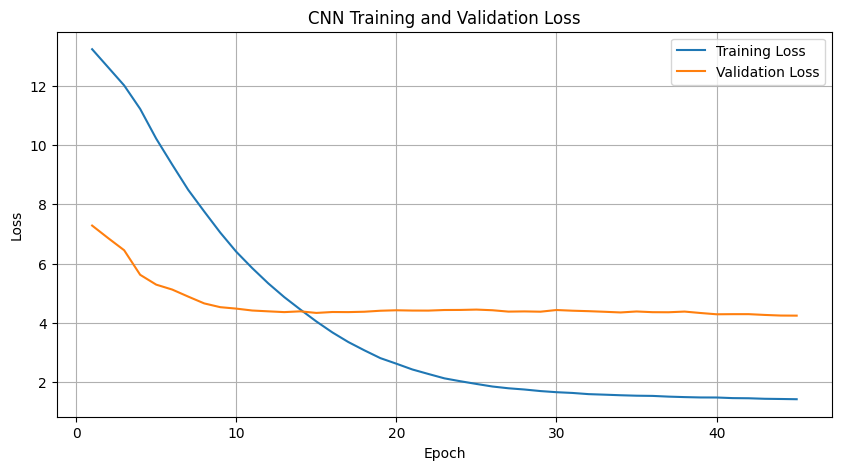

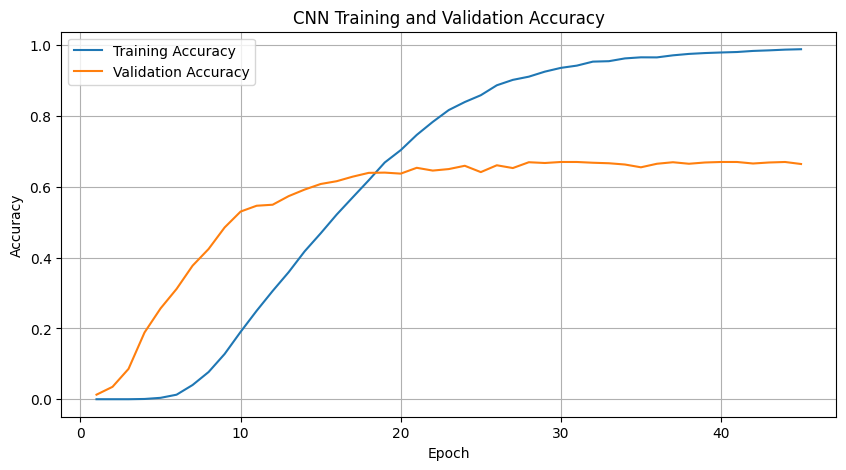

In [47]:
# ============================================================
# CELL 24: Plot training curves
# ============================================================

epochs = range(

    1,

    len(
        history["train_loss"]
    ) + 1

)


plt.figure(
    figsize=(10, 5)
)


plt.plot(

    epochs,

    history[
        "train_loss"
    ],

    label="Training Loss"

)


plt.plot(

    epochs,

    history[
        "validation_loss"
    ],

    label="Validation Loss"

)


plt.xlabel(
    "Epoch"
)


plt.ylabel(
    "Loss"
)


plt.title(
    "CNN Training and Validation Loss"
)


plt.legend()


plt.grid()


plt.show()


# ------------------------------------------------------------


plt.figure(
    figsize=(10, 5)
)


plt.plot(

    epochs,

    history[
        "train_accuracy"
    ],

    label="Training Accuracy"

)


plt.plot(

    epochs,

    history[
        "validation_accuracy"
    ],

    label="Validation Accuracy"

)


plt.xlabel(
    "Epoch"
)


plt.ylabel(
    "Accuracy"
)


plt.title(
    "CNN Training and Validation Accuracy"
)


plt.legend()


plt.grid()


plt.show()

In [48]:
# ============================================================
# CELL 25: Load best saved model
# ============================================================

checkpoint = torch.load(
    MODEL_PATH, map_location=DEVICE, weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])

print("Best model loaded successfully.")
print("\nBackbone:", checkpoint.get("backbone"))
print("Best epoch:", checkpoint["epoch"])
print("Best validation loss:", checkpoint["validation_loss"])
print("Best validation accuracy:", checkpoint["validation_accuracy"])


Best model loaded successfully.

Backbone: resnet34
Best epoch: 30
Best validation loss: 4.434869698115757
Best validation accuracy: 0.67


In [49]:
# ============================================================
# CELL 26: Final closed-set baseline evaluation (with TTA)
# ============================================================

test_loss, test_accuracy = evaluate(model, test_loader, criterion)

test_top5 = evaluate_topk(model, test_loader, k=5)


# ------------------------------------------------------------
# Test-time augmentation
# ------------------------------------------------------------
# Averaging logits over the original image and two small affine
# variants is usually worth roughly +1% at zero training cost.

@torch.no_grad()
def evaluate_with_tta(model, dataloader):

    model.eval()

    predictions = []
    targets = []

    for images, labels in tqdm(dataloader, desc="TTA", leave=False):

        images = images.to(DEVICE, non_blocking=True)

        if USE_CHANNELS_LAST:
            images = images.to(memory_format=torch.channels_last)

        logits = model(images).float().softmax(dim=1)

        for angle in (-5.0, 5.0):

            rotated = transforms.functional.rotate(images, angle)

            logits = logits + model(rotated).float().softmax(dim=1)

        predictions.extend(torch.argmax(logits, dim=1).cpu().numpy())
        targets.extend(labels.numpy())

    return accuracy_score(targets, predictions)


test_accuracy_tta = evaluate_with_tta(model, test_loader)


print("=" * 60)
print("FINAL CLOSED-SET CNN BASELINE RESULTS")
print("=" * 60)

print(f"\nTest Loss: {test_loss:.4f}")
print(f"Test Accuracy (Rank-1): {test_accuracy:.4f}")
print(f"Test Accuracy (Rank-1, with TTA): {test_accuracy_tta:.4f}")
print(f"Test Accuracy (Rank-5): {test_top5:.4f}")


FINAL CLOSED-SET CNN BASELINE RESULTS

Test Loss: 3.9160
Test Accuracy (Rank-1): 0.7171
Test Accuracy (Rank-1, with TTA): 0.7214
Test Accuracy (Rank-5): 0.7779


In [50]:
# ============================================================
# CELL 27: Save training history
# ============================================================

history_df = pd.DataFrame(
    history
)


history_path = OUTPUT_DIR / (
    "training_history.csv"
)


history_df.to_csv(

    history_path,

    index=False

)


print(
    "Training history saved:"
)


print(
    history_path
)

Training history saved:
..\classical_cnn_baseline\training_history.csv


In [51]:
# ============================================================
# CELL 28: Final notebook summary
# ============================================================

print("=" * 60)

print(
    "NOTEBOOK 4 COMPLETED SUCCESSFULLY"
)

print("=" * 60)


print(
    "\nClassical CNN baseline summary:"
)


print(
    f"Number of identities: "
    f"{NUM_CLASSES}"
)


print(
    f"Training images: "
    f"{len(baseline_train_df)}"
)


print(
    f"Validation images: "
    f"{len(baseline_validation_df)}"
)


print(
    f"Closed-set test images: "
    f"{len(baseline_test_df)}"
)


print(
    f"\nBest validation accuracy: "
    f"{best_validation_accuracy:.4f}"
)


print(
    f"Closed-set test accuracy: "
    f"{test_accuracy:.4f}"
)


print(
    "\nSaved model:"
)


print(
    MODEL_PATH
)


print(
    "\nOutput directory:"
)


print(
    OUTPUT_DIR
)

NOTEBOOK 4 COMPLETED SUCCESSFULLY

Classical CNN baseline summary:
Number of identities: 1400
Training images: 11200
Validation images: 1400
Closed-set test images: 1400

Best validation accuracy: 0.6700
Closed-set test accuracy: 0.7171

Saved model:
..\classical_cnn_baseline\best_classical_cnn_resnet34.pth

Output directory:
..\classical_cnn_baseline
